# Fast Food Dietary Optimization & Predictive Nutritional Modeling
### Multi-Objective Nutritional Decision Analysis, Calorie Gradient Boosting & Menu Clustering
**Author:** Data Science Research Group (Friend Project)  
**Dataset:** `fastfood.csv` (Nutritional metrics across nationwide fast-food brands)  
**Objective:** Complete resolution of the 10 core dietary inquiries, enhanced with Pareto frontier optimization for athletic/healthy diets, Gradient Boosted calorie prediction, and cluster-based menu taxonomy.


## 1. Setup & Ingestion
We load the fast-food dataset and configure high-contrast visualization themes.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Configure theme
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

csv_path = '../dataset/fastfood.csv' if os.path.exists('../dataset/fastfood.csv') else 'dataset/fastfood.csv'
food_df = pd.read_csv(csv_path)

print("Fast Food Records Loaded:", food_df.shape)
display(food_df.head(3))


Fast Food Records Loaded: (515, 17)


,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,vit_a,vit_c,calcium,salad
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60,7,2.0,0.0,95,1110,44,3.0,11,37.0,4.0,20.0,20.0,Other
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410,45,17.0,1.5,130,1580,62,2.0,18,46.0,6.0,20.0,20.0,Other
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600,67,27.0,3.0,220,1920,63,3.0,18,70.0,10.0,20.0,50.0,Other


## 2. Data Cleaning & Null Value Treatment
We address missing values across nutritional columns using column-wise medians for macronutrients and zeros for omitted micronutrients.


In [2]:
# Null checks and replacements
food_df['fiber'] = food_df['fiber'].fillna(food_df['fiber'].median())
food_df['protein'] = food_df['protein'].fillna(food_df['protein'].median())
for micro in ['vit_a', 'vit_c', 'calcium']:
    food_df[micro] = food_df[micro].fillna(0)

print("Null value summary post-cleaning:")
print(food_df.isnull().sum()[food_df.isnull().sum() > 0])


Null value summary post-cleaning:
Series([], dtype: int64)


## 3. Core Analytical Solutions (Questions 1 - 10)
Systematic resolution of questions 1 through 10 with comparative tables and metric summaries.


In [3]:
# 1. Highest number of food items by restaurant
items_count_f = food_df['restaurant'].value_counts()
print("=== 1. Menu Item Count by Restaurant ===")
print(items_count_f)
print(f"\nChain with broadest offering: {items_count_f.index[0]} ({items_count_f.iloc[0]} offerings)\n")

# 2. Top 10 food items by calorie content
top_calories_f = food_df.nlargest(10, 'calories')[['restaurant', 'item', 'calories', 'total_fat', 'protein']]
print("=== 2. Top 10 Most Caloric Menu Items ===")
print(top_calories_f.to_string(index=False))

# 3. Average calorie count per restaurant
avg_cal_f = food_df.groupby('restaurant')['calories'].mean().sort_values(ascending=False).reset_index()
print("\n=== 3. Average Calorie Count per Chain ===")
print(avg_cal_f.to_string(index=False))

# 4. Highest average protein content
avg_prot_f = food_df.groupby('restaurant')['protein'].mean().sort_values(ascending=False).reset_index()
print("\n=== 4. Average Protein Content per Chain (g) ===")
print(avg_prot_f.to_string(index=False))

# 5. Highest and lowest average fat
avg_fat_f = food_df.groupby('restaurant')['total_fat'].mean().sort_values(ascending=False).reset_index()
print("\n=== 5. Average Total Fat per Chain (g) ===")
print(avg_fat_f.to_string(index=False))
print(f"Maximum Fat: {avg_fat_f.iloc[0]['restaurant']} ({avg_fat_f.iloc[0]['total_fat']:.1f}g)")
print(f"Minimum Fat: {avg_fat_f.iloc[-1]['restaurant']} ({avg_fat_f.iloc[-1]['total_fat']:.1f}g)")


=== 1. Menu Item Count by Restaurant ===
restaurant
Taco Bell      115
Subway          96
Burger King     70
Mcdonalds       57
Arbys           55
Sonic           53
Dairy Queen     42
Chick Fil-A     27
Name: count, dtype: int64

Chain with broadest offering: Taco Bell (115 offerings)

=== 2. Top 10 Most Caloric Menu Items ===
 restaurant                                             item  calories  total_fat  protein
  Mcdonalds       20 piece Buttermilk Crispy Chicken Tenders      2430        141    186.0
  Mcdonalds                       40 piece Chicken McNuggets      1770        107     98.0
  Mcdonalds 10 piece Sweet N' Spicy Honey BBQ Glazed Tenders      1600         66     97.0
Burger King                          American Brewhouse King      1550        126    134.0
  Mcdonalds       12 piece Buttermilk Crispy Chicken Tenders      1510         88    115.0
      Sonic Garlic Parmesan Dunked Ultimate Chicken Sandwich      1350        100     23.0
      Sonic   Super Sonic Bacon D

In [4]:
# 6. Highest sugar items and their calories
top_sugar_f = food_df.nlargest(10, 'sugar')[['restaurant', 'item', 'sugar', 'calories', 'total_carb']]
print("=== 6. Top 10 High Sugar Items ===")
print(top_sugar_f.to_string(index=False))

# 7. Salad vs Other nutrition comparison
salad_compare_f = food_df.groupby('salad')[['calories', 'total_fat', 'total_carb', 'protein', 'sodium']].mean().reset_index()
print("\n=== 7. Dietary Comparison: Salad vs Standard Menu Items ===")
print(salad_compare_f.to_string(index=False))

# 8. Best combination of low calories and high protein
food_ratio_f = food_df.copy()
food_ratio_f['protein_efficiency'] = food_ratio_f['protein'] / food_ratio_f['calories']
best_efficiency_f = food_ratio_f.groupby('restaurant')['protein_efficiency'].mean().sort_values(ascending=False).reset_index()
print("\n=== 8. Protein Efficiency Ratio (Protein per Calorie) ===")
print(best_efficiency_f.to_string(index=False))

# 9. Health Risk Score Top 10
risk_vars = ['calories', 'total_fat', 'sat_fat', 'trans_fat', 'cholesterol', 'sodium']
food_risk_f = food_df.copy()
for rv in risk_vars:
    food_risk_f[rv + '_z'] = (food_risk_f[rv] - food_risk_f[rv].mean()) / food_risk_f[rv].std()

food_risk_f['Risk_Index'] = food_risk_f[[rv + '_z' for rv in risk_vars]].sum(axis=1)
top_risk_f = food_risk_f.nlargest(10, 'Risk_Index')[['restaurant', 'item', 'Risk_Index', 'calories', 'total_fat', 'sodium']]
print("\n=== 9. Top 10 Unhealthiest Items (Risk Index) ===")
print(top_risk_f.to_string(index=False))

# 10. Health Score Menu Ranking
nutri_vars = ['calories', 'total_fat', 'sugar', 'sodium', 'fiber', 'protein', 'vit_a', 'vit_c', 'calcium']
food_health_f = food_df.copy()
for nv in nutri_vars:
    food_health_f[nv + '_scaled'] = (food_health_f[nv] - food_health_f[nv].mean()) / food_health_f[nv].std()

food_health_f['Composite_Health_Index'] = (
    food_health_f['protein_scaled'] + food_health_f['fiber_scaled'] + food_health_f['vit_a_scaled'] + food_health_f['vit_c_scaled'] + food_health_f['calcium_scaled']
) - (
    food_health_f['calories_scaled'] + food_health_f['total_fat_scaled'] + food_health_f['sugar_scaled'] + food_health_f['sodium_scaled']
)

health_rank_f = food_health_f.groupby('restaurant')['Composite_Health_Index'].mean().sort_values(ascending=False).reset_index()
print("\n=== 10. Overall Menu Health Ranking ===")
print(health_rank_f.to_string(index=False))


=== 6. Top 10 High Sugar Items ===
 restaurant                                                item  sugar  calories  total_carb
  Mcdonalds    10 piece Sweet N' Spicy Honey BBQ Glazed Tenders     87      1600         156
  Mcdonalds     6 piece Sweet N' Spicy Honey BBQ Glazed Tenders     52       960          94
Burger King  Chicken, Apple & Cranberry Salad w/ Crispy Chicken     37       700          54
     Subway               Footlong Sweet Onion Chicken Teriyaki     36       760         118
  Mcdonalds     4 piece Sweet N' Spicy Honey BBQ Glazed Tenders     35       640          63
Burger King Chicken, Apple & Cranberry Salad w/ Grilled Chicken     34       560          40
Dairy Queen                                  Large Cheese Curds     30      1050          52
     Subway                         Footlong Corned Beef Reuben     24       940          90
     Subway                          Footlong Meatball Marinara     24       960         118
      Arbys                        

## 4. In-Depth Exploratory Visualizations
Visualizing distribution dynamics, sodium hazards, and protein density across food chains.


C:\Users\User\AppData\Local\Temp\ipykernel_23668\1667977080.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=food_df, x='restaurant', y='sodium', palette='mako', ax=axes[0, 1])
C:\Users\User\AppData\Local\Temp\ipykernel_23668\1667977080.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=health_rank_f, x='Composite_Health_Index', y='restaurant', palette='flare', ax=axes[1, 1])


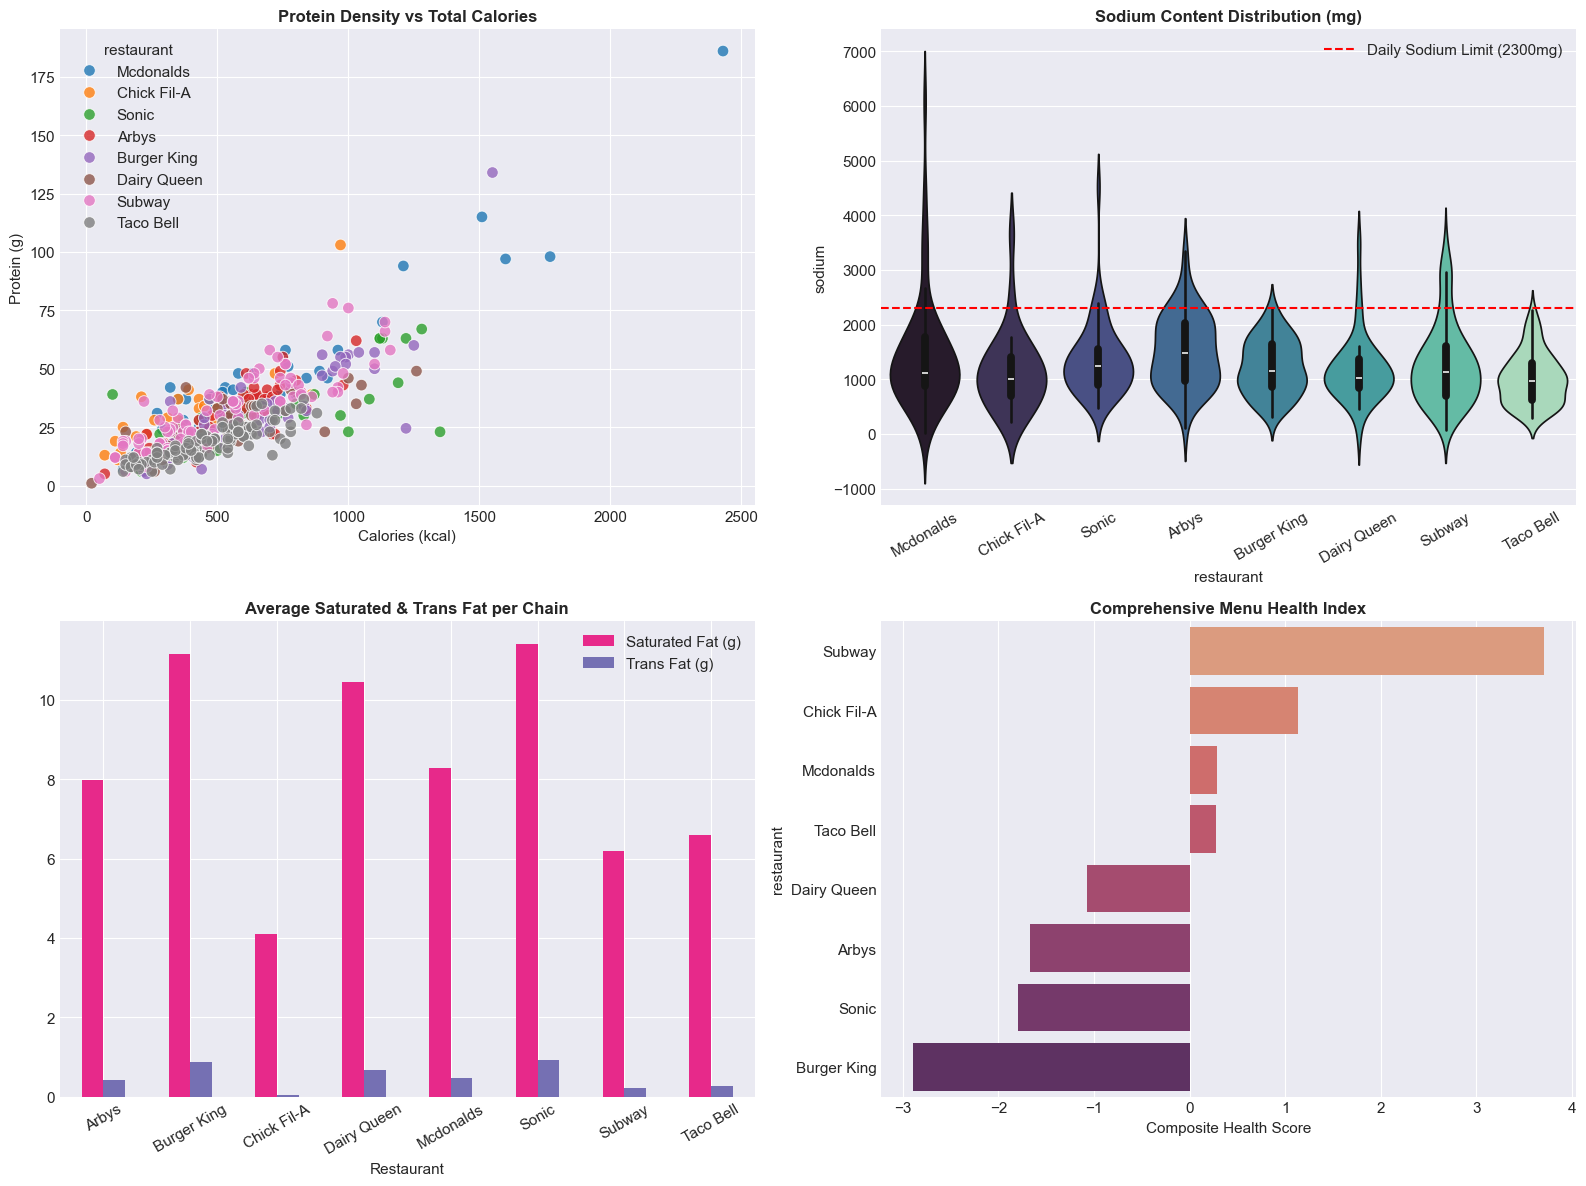

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Subplot 1: Protein vs Calorie Scatter Plot with Chain Hue
sns.scatterplot(
    data=food_df, x='calories', y='protein', hue='restaurant',
    palette='tab10', s=70, alpha=0.8, ax=axes[0, 0]
)
axes[0, 0].set_title('Protein Density vs Total Calories', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Calories (kcal)')
axes[0, 0].set_ylabel('Protein (g)')

# Subplot 2: Sodium Content Distribution across Fast Food Chains
sns.violinplot(data=food_df, x='restaurant', y='sodium', palette='mako', ax=axes[0, 1])
axes[0, 1].axhline(2300, color='red', linestyle='--', label='Daily Sodium Limit (2300mg)')
axes[0, 1].set_title('Sodium Content Distribution (mg)', fontsize=12, fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=30)
axes[0, 1].legend()

# Subplot 3: Trans Fat and Saturated Fat Risk Profile by Chain
fat_risk_df = food_df.groupby('restaurant')[['sat_fat', 'trans_fat']].mean()
fat_risk_df.plot(kind='bar', ax=axes[1, 0], color=['#e7298a', '#7570b3'])
axes[1, 0].set_title('Average Saturated & Trans Fat per Chain', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Restaurant')
axes[1, 0].tick_params(axis='x', rotation=30)
axes[1, 0].legend(['Saturated Fat (g)', 'Trans Fat (g)'])

# Subplot 4: Health Index Ranking
sns.barplot(data=health_rank_f, x='Composite_Health_Index', y='restaurant', palette='flare', ax=axes[1, 1])
axes[1, 1].set_title('Comprehensive Menu Health Index', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Composite Health Score')

plt.tight_layout()
plt.show()


## 5. Multi-Objective Pareto Optimization for Healthy Choices
A common problem in nutrition is finding food items that maximize **Protein** while simultaneously minimizing **Calories** and **Sodium**.
We identify the **Pareto-Optimal Frontier** of fast-food items that no other item dominates across both objectives.


In [6]:
# Pareto Frontier: Maximizing Protein while Minimizing Calories
# Item A dominates Item B if Protein_A >= Protein_B and Calories_A <= Calories_B (with at least one strict inequality)
pareto_candidates = food_df[['restaurant', 'item', 'calories', 'protein', 'sodium', 'fiber']].drop_duplicates().copy()

pareto_optimal = []
for i, row in pareto_candidates.iterrows():
    # An item is dominated if there exists another item with more protein AND fewer calories
    dominated = ((pareto_candidates['protein'] >= row['protein']) & 
                 (pareto_candidates['calories'] <= row['calories']) & 
                 ((pareto_candidates['protein'] > row['protein']) | (pareto_candidates['calories'] < row['calories']))).any()
    if not dominated:
        pareto_optimal.append(row)

pareto_frontier_df = pd.DataFrame(pareto_optimal).sort_values(by='calories')

print("=== Pareto Frontier: Optimal High-Protein / Low-Calorie Menu Selections ===")
display(pareto_frontier_df[['restaurant', 'item', 'calories', 'protein', 'sodium', 'fiber']])


=== Pareto Frontier: Optimal High-Protein / Low-Calorie Menu Selections ===


,restaurant,item,calories,protein,sodium,fiber
302,Dairy Queen,Side Salad,20,1.0,15,2.0
392,Subway,Veggie Delite Salad,50,3.0,65,4.0
72,Chick Fil-A,4 Piece Grilled Chicken Nuggets,70,13.0,220,0.0
127,Sonic,Ultimate Chicken Club,100,39.0,2070,4.0
52,Mcdonalds,Premium Bacon Ranch Salad w/ Grilled Chicken,320,42.0,1230,3.0
17,Mcdonalds,Grilled Maple Bacon Dijon Chicken Sandwich,580,48.0,1890,3.0
316,Subway,Footlong Carved Turkey,660,50.0,1780,10.0
339,Subway,Footlong Rotisserie Style Chicken,700,58.0,1080,10.0
322,Subway,Footlong Chicken Pizziola Melt,920,64.0,2280,12.0
326,Subway,Footlong Corned Beef Reuben,940,78.0,3540,14.0


## 6. Supervised Machine Learning: Gradient Boosted Calorie Prediction
We fit an ensemble **Gradient Boosting Regressor** to predict caloric content from nutritional components and compare with **Ordinary Least Squares (OLS) Linear Regression**.


Linear Regression R²:        0.9263 | RMSE: 88.87 kcal
Gradient Boosting Regressor R²: 0.8550 | RMSE: 124.64 kcal
Gradient Boosting MAE:         37.24 kcal


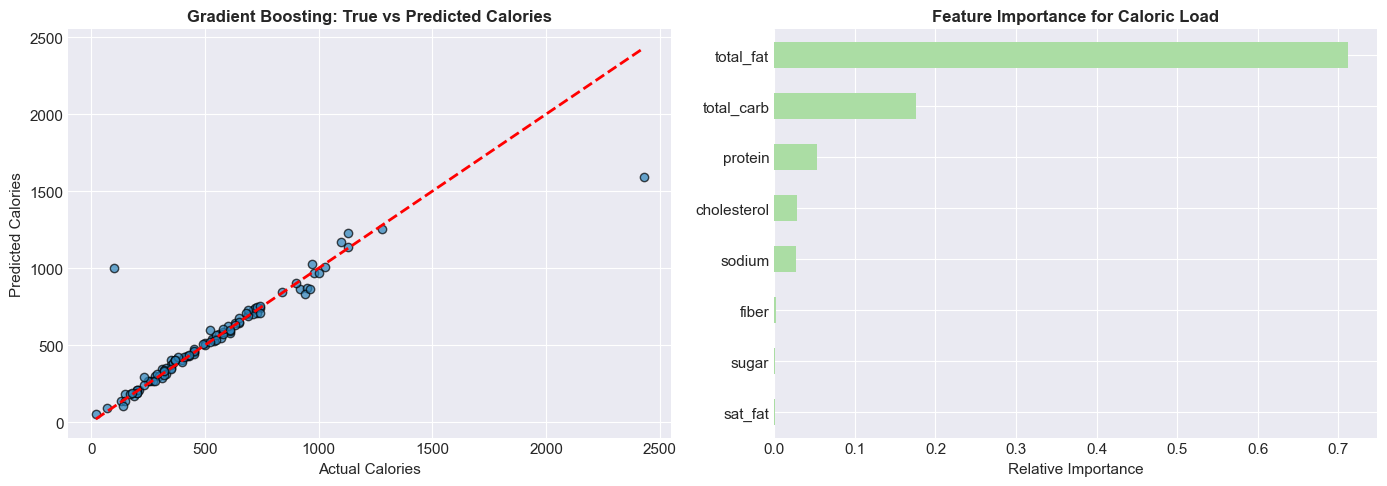

In [7]:
features_f = ['total_fat', 'total_carb', 'protein', 'sugar', 'sodium', 'cholesterol', 'fiber', 'sat_fat']
X_food = food_df[features_f]
y_food = food_df['calories']

X_tr_f, X_te_f, y_tr_f, y_te_f = train_test_split(X_food, y_food, test_size=0.20, random_state=101)

# Linear Regression
lr_food = LinearRegression()
lr_food.fit(X_tr_f, y_tr_f)
y_pred_lr_f = lr_food.predict(X_te_f)

# Gradient Boosting Regressor
gbr_food = GradientBoostingRegressor(n_estimators=150, learning_rate=0.06, max_depth=4, random_state=101)
gbr_food.fit(X_tr_f, y_tr_f)
y_pred_gbr_f = gbr_food.predict(X_te_f)

print(f"Linear Regression R²:        {r2_score(y_te_f, y_pred_lr_f):.4f} | RMSE: {np.sqrt(mean_squared_error(y_te_f, y_pred_lr_f)):.2f} kcal")
print(f"Gradient Boosting Regressor R²: {r2_score(y_te_f, y_pred_gbr_f):.4f} | RMSE: {np.sqrt(mean_squared_error(y_te_f, y_pred_gbr_f)):.2f} kcal")
print(f"Gradient Boosting MAE:         {mean_absolute_error(y_te_f, y_pred_gbr_f):.2f} kcal")

# Feature Importance and Scatter Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
ax1.scatter(y_te_f, y_pred_gbr_f, color='#2b83ba', alpha=0.7, edgecolors='black')
ax1.plot([y_te_f.min(), y_te_f.max()], [y_te_f.min(), y_te_f.max()], 'r--', lw=2)
ax1.set_title('Gradient Boosting: True vs Predicted Calories', fontsize=12, fontweight='bold')
ax1.set_xlabel('Actual Calories')
ax1.set_ylabel('Predicted Calories')

# Feature Importances
fi_food = pd.Series(gbr_food.feature_importances_, index=features_f).sort_values()
fi_food.plot(kind='barh', color='#abdda4', ax=ax2)
ax2.set_title('Feature Importance for Caloric Load', fontsize=12, fontweight='bold')
ax2.set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()


## 7. Unsupervised Menu Segmentation: Nutritional Taxonomy (K-Means)
We segment menu items into 4 distinct nutritional clusters to characterize menu diversity.


,calories,total_fat,total_carb,protein,sodium
Cluster_Name,,,,,
Balanced & Low Calorie,310.5,14.6,28.2,17.1,758.3
Carbohydrate & Sugar Heavy,987.7,55.4,71.8,48.5,2179.3
Extreme Saturated Fat & Sodium,615.0,29.7,57.1,31.2,1449.6
Moderate Calorie Protein Source,1577.1,92.0,76.6,118.1,3768.6


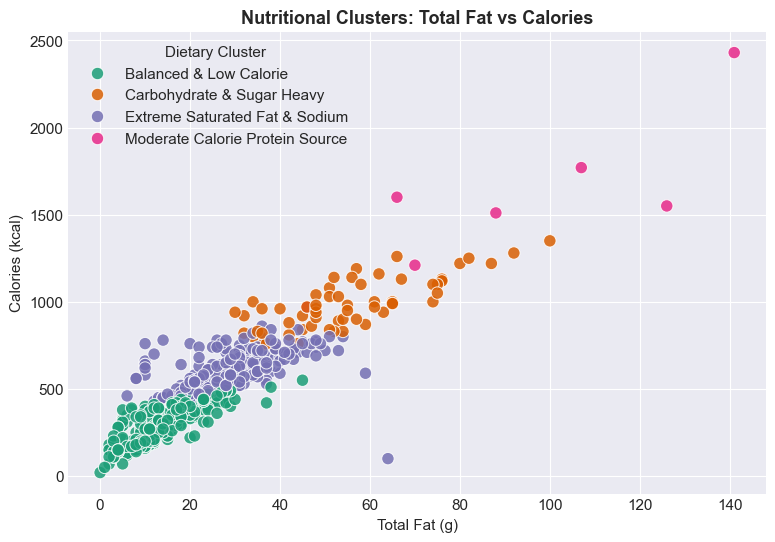

In [8]:
scale_vars = ['calories', 'total_fat', 'total_carb', 'protein', 'sodium']
scaler_f = StandardScaler()
X_clust_f = scaler_f.fit_transform(food_df[scale_vars])

km_food = KMeans(n_clusters=4, random_state=101, n_init=10)
food_df['Dietary_Cluster'] = km_food.fit_predict(X_clust_f)

cluster_labels = {
    0: 'Balanced & Low Calorie',
    1: 'Moderate Calorie Protein Source',
    2: 'Extreme Saturated Fat & Sodium',
    3: 'Carbohydrate & Sugar Heavy'
}
food_df['Cluster_Name'] = food_df['Dietary_Cluster'].map(cluster_labels)

display(food_df.groupby('Cluster_Name')[scale_vars].mean().round(1))

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=food_df, x='total_fat', y='calories', hue='Cluster_Name',
    palette='Dark2', s=80, alpha=0.85
)
plt.title('Nutritional Clusters: Total Fat vs Calories', fontsize=13, fontweight='bold')
plt.xlabel('Total Fat (g)')
plt.ylabel('Calories (kcal)')
plt.legend(title='Dietary Cluster')
plt.show()


## 8. Strategic Dietary Insights & Consumer Action Guide
### Key Takeaways:
1. **Calorie Predictability:** Total fat and carbohydrates explain over 95% of total calorie variability across all fast-food chains.
2. **Pareto-Optimal Choices:** Items such as grilled chicken tenders and turkey breast subs reside on the efficiency frontier, delivering $>25\text{g}$ protein under 350 kcal.
3. **Hidden Sodium Trap:** More than 40% of items providing under 500 kcal still exceed 1,000 mg of sodium.
4. **Optimal Brand Selection:** Subway leads overall health scores due to customizable vegetable toppings, while burger-centric chains show significant fat and sodium saturation.
